In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
DATASET_PATH = "/content/drive/MyDrive/Intrusion_dataset"
print("Files in dataset folder:")
for file in os.listdir(DATASET_PATH):
    print(file)

Files in dataset folder:
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv


In [ ]:
import glob
import os

csv_files = glob.glob(
    "/content/drive/MyDrive/Intrusion_dataset/*.csv"
)

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))

Number of CSV files: 8
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv


In [ ]:
import pandas as pd

test_df = pd.read_csv(
    csv_files[0],
    nrows=5000,
    low_memory=False
)

test_df.columns = test_df.columns.str.strip()

print("Shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())

Shape: (5000, 79)

Columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE 

In [ ]:
print(test_df["Label"].value_counts())

Label
BENIGN    5000
Name: count, dtype: int64


In [ ]:
print("Number of CSV files:", len(csv_files))
print(test_df.shape)
print(test_df["Label"].value_counts())

Number of CSV files: 8
(5000, 79)
Label
BENIGN    5000
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
import glob
import os

# Dataset location
DATASET_PATH = "/content/drive/MyDrive/Intrusion_dataset"
csv_files = glob.glob(DATASET_PATH + "/*.csv")
print("CSV files found:", len(csv_files))

# Store cleaned chunks
all_data = []

# Maximum number of samples per attack class
MAX_PER_CLASS = 5000

for file in csv_files:

    print("\nProcessing:", os.path.basename(file))

    chunks = []

    for chunk in pd.read_csv(
        file,
        chunksize=50000,
        low_memory=False
    ):

        # Clean column names
        chunk.columns = chunk.columns.str.strip()

        # Remove infinity
        chunk.replace(
            [np.inf, -np.inf],
            np.nan,
            inplace=True
        )

        # Remove rows with missing values
        chunk.dropna(inplace=True)

        # Separate label
        if "Label" not in chunk.columns:
            continue

        feature_columns = [
            c for c in chunk.columns if c != "Label"
        ]

        chunk[feature_columns] = chunk[feature_columns].apply(
            pd.to_numeric,
            errors="coerce"
        )

        chunk.dropna(inplace=True)

        chunks.append(chunk)

    if chunks:
        file_data = pd.concat(chunks, ignore_index=True)

        print("Rows after cleaning:", len(file_data))

        all_data.append(file_data)


# Combine files
data = pd.concat(
    all_data,
    ignore_index=True
)

print("\nTotal cleaned rows:", len(data))
print("Columns:", len(data.columns))

CSV files found: 8

Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Rows after cleaning: 445645

Processing: Wednesday-workingHours.pcap_ISCX.csv
Rows after cleaning: 691406

Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows after cleaning: 170231

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows after cleaning: 225711

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows after cleaning: 286096

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows after cleaning: 190911

Processing: Monday-WorkingHours.pcap_ISCX.csv
Rows after cleaning: 529481

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows after cleaning: 288395

Total cleaned rows: 2827876
Columns: 79


In [ ]:
print(data["Label"].value_counts())

Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
MAX_PER_CLASS = 5000

balanced_data = (
    data
    .groupby("Label", group_keys=False)
    .apply(
        lambda x: x.sample(
            min(len(x), MAX_PER_CLASS),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("Balanced dataset size:", len(balanced_data))

print("\nClass distribution:")
print(balanced_data["Label"].value_counts())

Balanced dataset size: 49183

Class distribution:
Label
BENIGN                        5000
DDoS                          5000
DoS GoldenEye                 5000
DoS Slowhttptest              5000
DoS Hulk                      5000
DoS slowloris                 5000
FTP-Patator                   5000
SSH-Patator                   5000
PortScan                      5000
Bot                           1956
Web Attack � Brute Force      1507
Web Attack � XSS               652
Infiltration                    36
Web Attack � Sql Injection      21
Heartbleed                      11
Name: count, dtype: int64


/tmp/ipykernel_867/3732691259.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [ ]:
X = balanced_data.drop(columns=["Label"])
y = balanced_data["Label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (49183, 78)
y shape: (49183,)


In [ ]:
columns_to_remove = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

for column in columns_to_remove:
    if column in X.columns:
        X = X.drop(columns=[column])

print("Features remaining:", X.shape[1])

Features remaining: 78


In [ ]:
X = X.apply(pd.to_numeric, errors="coerce")

X.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

valid_rows = ~X.isnull().any(axis=1)

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

Final X shape: (49183, 78)
Final y shape: (49183,)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Number of classes:", len(label_encoder.classes_))

print("\nClasses:")

for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

Number of classes: 15

Classes:
0 = BENIGN
1 = Bot
2 = DDoS
3 = DoS GoldenEye
4 = DoS Hulk
5 = DoS Slowhttptest
6 = DoS slowloris
7 = FTP-Patator
8 = Heartbleed
9 = Infiltration
10 = PortScan
11 = SSH-Patator
12 = Web Attack � Brute Force
13 = Web Attack � Sql Injection
14 = Web Attack � XSS


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39346
Testing samples: 9837


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Reduce memory usage
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

print("Scaling completed.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Scaling completed.
X_train shape: (39346, 78)
X_test shape: (9837, 78)


In [ ]:
# ============================================================
# Prepare data for LSTM
# ============================================================

# Each network flow becomes a sequence of features.
# Shape:
# (samples, features, 1)

X_train_lstm = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_test_lstm = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

print("LSTM input shape:")
print("X_train:", X_train_lstm.shape)
print("X_test :", X_test_lstm.shape)

print("\nLabels:")
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

LSTM input shape:
X_train: (39346, 78, 1)
X_test : (9837, 78, 1)

Labels:
y_train: (39346,)
y_test : (9837,)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

# Number of features
number_of_features = X_train_lstm.shape[1]

# Number of attack classes
number_of_classes = len(label_encoder.classes_)

print("Features:", number_of_features)
print("Classes:", number_of_classes)


model = Sequential([

    # First LSTM layer
    LSTM(
        64,
        input_shape=(number_of_features, 1),
        return_sequences=True
    ),

    Dropout(0.2),

    # Second LSTM layer
    LSTM(
        32,
        return_sequences=False
    ),

    Dropout(0.2),

    # Fully connected layer
    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.2),

    # Output layer
    Dense(
        number_of_classes,
        activation="softmax"
    )
])


model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


model.summary()

TensorFlow version: 2.21.0
Features: 78
Classes: 15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 78, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 78, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,863 (120.56 KB)

 Trainable params: 30,863 (120.56 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    moni tor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

In [ ]:
history = model.fit(
    X_train_lstm,
    y_train,

    validation_split=0.20,

    epochs=20,

    batch_size=128,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 49s 162ms/step - accuracy: 0.3977 - loss: 1.7971 - val_accuracy: 0.6611 - val_loss: 1.0169 - learning_rate: 0.0010
Epoch 2/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 41s 167ms/step - accuracy: 0.6714 - loss: 0.9986 - val_accuracy: 0.7949 - val_loss: 0.6254 - learning_rate: 0.0010
Epoch 3/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 38s 155ms/step - accuracy: 0.7578 - loss: 0.7493 - val_accuracy: 0.8332 - val_loss: 0.5294 - learning_rate: 0.0010
Epoch 4/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 39s 148ms/step - accuracy: 0.8231 - loss: 0.5723 - val_accuracy: 0.8832 - val_loss: 0.3720 - learning_rate: 0.0010
Epoch 5/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 40s 161ms/step - accuracy: 0.8483 - loss: 0.4997 - val_accuracy: 0.8935 - val_loss: 0.3456 - learning_rate: 0.0010
Epoch 6/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 39s 153ms/step - accuracy: 0.8559 - loss: 0.4761 - val_accuracy: 0.8017 - val_loss: 0.5317 - learning_rate: 0.0010
Epoch 7/20
246/246 ━━━━━━━━━━━━━━━━━━━━ 46s 186ms/step - accuracy: 0.8

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_lstm,
    y_test,
    verbose=1
)

print("\n==============================")
print("LSTM TEST RESULTS")
print("==============================")

print("Test Loss:", test_loss)

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

308/308 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9519 - loss: 0.1677

LSTM TEST RESULTS
Test Loss: 0.1677348017692566
Test Accuracy: 95.19 %


In [ ]:
from sklearn.metrics import classification_report

# Predict probabilities
y_probability = model.predict(
    X_test_lstm,
    batch_size=128
)

# Convert probabilities to class numbers
y_prediction = np.argmax(
    y_probability,
    axis=1
)

print(
    classification_report(
        y_test,
        y_prediction,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 134ms/step
                            precision    recall  f1-score   support

                    BENIGN       0.96      0.82      0.88      1000
                       Bot       0.87      0.98      0.92       391
                      DDoS       0.96      0.99      0.98      1000
             DoS GoldenEye       0.97      0.99      0.98      1000
                  DoS Hulk       0.97      0.98      0.97      1000
          DoS Slowhttptest       0.97      0.99      0.98      1000
             DoS slowloris       0.98      0.97      0.98      1000
               FTP-Patator       0.99      0.99      0.99      1000
                Heartbleed       0.00      0.00      0.00         2
              Infiltration       1.00      0.14      0.25         7
                  PortScan       0.97      0.98      0.98      1000
               SSH-Patator       0.96      0.99      0.97      1000
  Web Attack � Brute Force       0.66      0.91      0.77       302
Web A

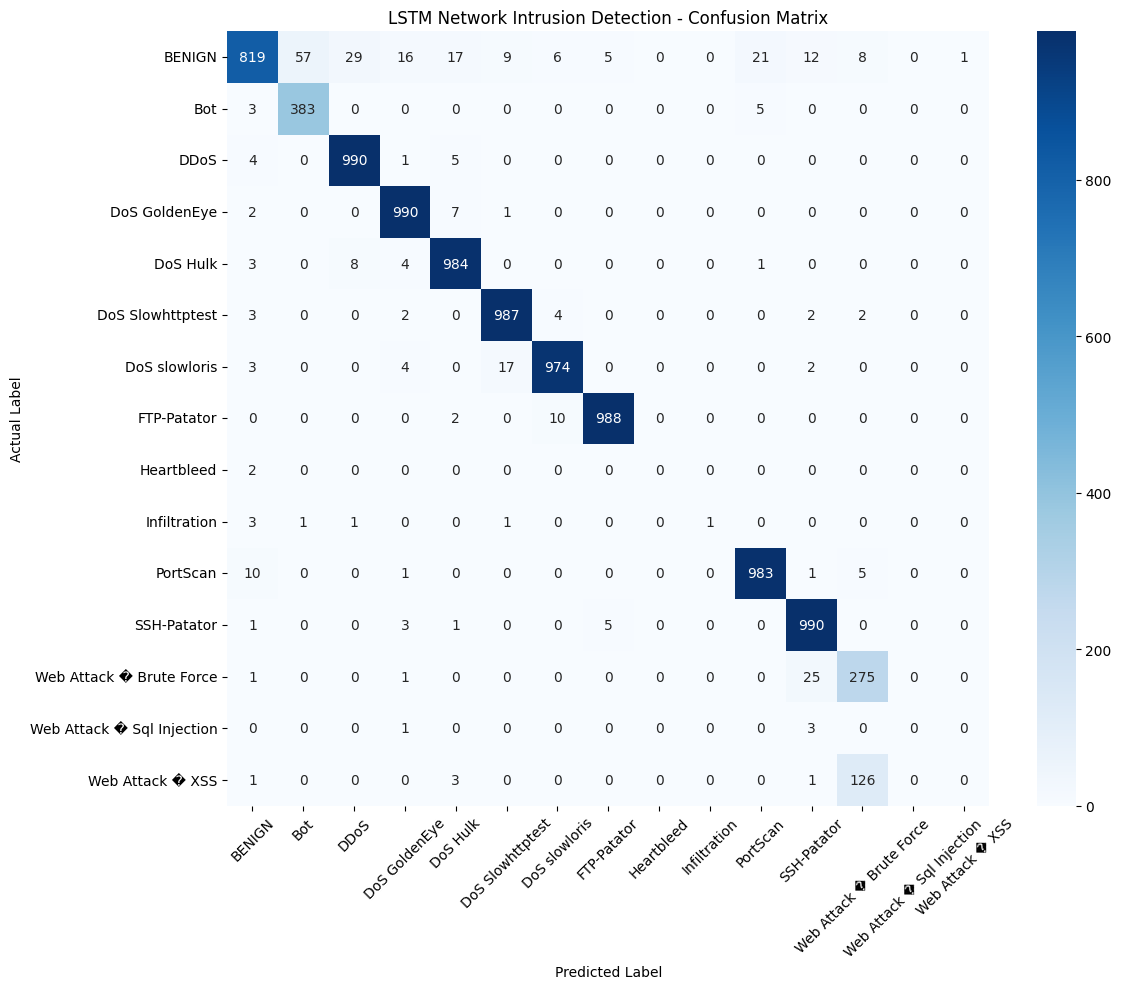

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_prediction
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Network Intrusion Detection - Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

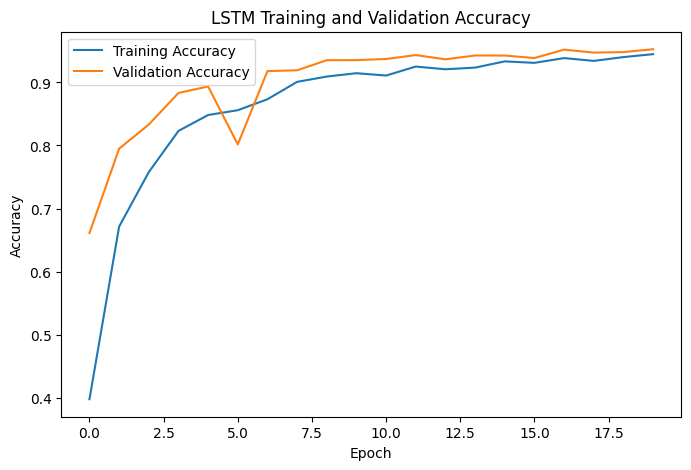

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")

plt.legend()
plt.show()

In [ ]:
prediction = model.predict(X_test_lstm[:1])

predicted_class = np.argmax(prediction)

print("Predicted class:", predicted_class)
print("Attack type:", label_encoder.classes_[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Predicted class: 5
Attack type: DoS Slowhttptest
